In [1]:
import pandas as pd

In [2]:
crop_df = pd.read_csv(r"C:\Users\Noman Traders\Downloads\crop_yield.csv")

In [3]:
crop_df.head(10)

,FARM_ID,CROP_TYPE,YIELD_KG,AREA_ACRES,HARVEST_DATE,DISTRICT,SEASON,FERTILIZER_USED,YIELD_VALUE
0,F001,Wheat,1500.0,4.0,01/01/2023,Sialkot,Rabi,Yes,30000
1,F002,Wheat,1500.0,5.0,02/01/2023,Multan,Rabi,No,30000
2,F003,Wheat,2500.0,5.0,03/01/2023,Faisalabad,Rabi,Yes,50000
3,F004,Wheat,1500.0,NaN,04/01/2023,Multan,Rabi,Yes,30000
4,F005,Rice,1500.0,4.0,05/01/2023,Faisalabad,Rabi,No,30000
5,F006,Rice,2000.0,6.0,06/01/2023,Faisalabad,Rabi,Yes,40000
6,F007,Maize,1500.0,6.0,07/01/2023,Faisalabad,Rabi,No,30000
7,F008,Wheat,1500.0,5.0,08/01/2023,Lahore,Rabi,No,30000
8,F009,Wheat,2000.0,5.0,09/01/2023,Faisalabad,Rabi,Yes,40000
9,F010,Wheat,1500.0,3.0,10/01/2023,Faisalabad,Rabi,Yes,30000


In [4]:
crop_df.isnull().sum()

FARM_ID              0
CROP_TYPE            0
YIELD_KG           330
AREA_ACRES         144
HARVEST_DATE         0
DISTRICT           126
SEASON               0
FERTILIZER_USED    318
YIELD_VALUE          0
dtype: int64

In [5]:
crop_df.dtypes

FARM_ID                str
CROP_TYPE              str
YIELD_KG           float64
AREA_ACRES         float64
HARVEST_DATE           str
DISTRICT               str
SEASON                 str
FERTILIZER_USED        str
YIELD_VALUE          int64
dtype: object

In [6]:
crop_df.describe()

,YIELD_KG,AREA_ACRES,YIELD_VALUE
count,2670.000000,2856.000000,3000.000000
mean,2014.232210,4.420168,39657.780000
std,407.846962,0.979259,8405.078755
min,1500.000000,3.000000,20068.000000
25%,1500.000000,4.000000,30000.000000
50%,2000.000000,4.000000,40000.000000
75%,2500.000000,5.000000,50000.000000
max,2500.000000,6.000000,50000.000000


In [7]:
crop_df.describe(include = "object")

C:\Users\Noman Traders\AppData\Local\Temp\ipykernel_5752\1372245271.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  crop_df.describe(include = "object")


,FARM_ID,CROP_TYPE,HARVEST_DATE,DISTRICT,SEASON,FERTILIZER_USED
count,3000,3000,3000,2874,3000,2682
unique,3000,4,3000,4,2,2
top,F001,Wheat,01/01/2023,Faisalabad,Rabi,Yes
freq,1,1158,1,936,1528,1776


DATA CLEANING

In [8]:
clean_crop = crop_df.copy()

In [9]:
clean_crop["AREA_ACRES"] = clean_crop["AREA_ACRES"].fillna(clean_crop["AREA_ACRES"].mean())

In [10]:
clean_crop["DISTRICT"] = clean_crop["DISTRICT"].fillna("UNKOWN")

In [11]:
clean_crop["FERTILIZER_USED"] = clean_crop["FERTILIZER_USED"].fillna("NO")

In [12]:
clean_crop["YIELD_VALUE"] = clean_crop["YIELD_VALUE"].fillna(clean_crop["YIELD_VALUE"].mean())

In [13]:
clean_crop["HARVEST_DATE"] = pd.to_datetime(clean_crop["HARVEST_DATE"], format = "%d/%m/%Y", errors = "coerce")

In [14]:
clean_crop["FARM_ID"] = clean_crop["FARM_ID"].str.replace("F", " ", regex=False)
clean_crop["FARM_ID"].astype(int)

0          1
1          2
2          3
3          4
4          5
        ... 
2995    2996
2996    2997
2997    2998
2998    2999
2999    3000
Name: FARM_ID, Length: 3000, dtype: int64

In [15]:
clean_crop.isnull().sum()

FARM_ID              0
CROP_TYPE            0
YIELD_KG           330
AREA_ACRES           0
HARVEST_DATE         0
DISTRICT             0
SEASON               0
FERTILIZER_USED      0
YIELD_VALUE          0
dtype: int64

In [16]:
clean_crop.dtypes

FARM_ID                       str
CROP_TYPE                     str
YIELD_KG                  float64
AREA_ACRES                float64
HARVEST_DATE       datetime64[us]
DISTRICT                      str
SEASON                        str
FERTILIZER_USED               str
YIELD_VALUE                 int64
dtype: object

In [17]:
yield_by_crop = clean_crop.groupby("CROP_TYPE")["YIELD_KG"].sum()

In [18]:
yield_by_crop

CROP_TYPE
Maize        1112500.0
Rice         1638000.0
Sugarcane     592000.0
Wheat        2035500.0
Name: YIELD_KG, dtype: float64

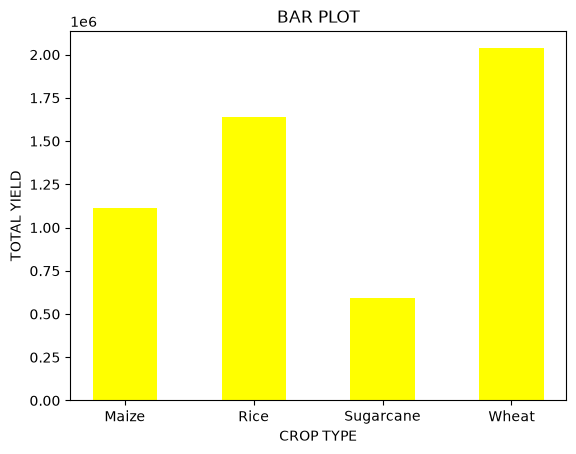

In [19]:
import matplotlib.pyplot as plt
plt.bar(yield_by_crop.index, yield_by_crop.values, color="yellow", width=0.5)
plt.xlabel("CROP TYPE")
plt.ylabel("TOTAL YIELD")
plt.title("BAR PLOT")
plt.show()

In [20]:
table = clean_crop.pivot_table(values="YIELD_KG", index="HARVEST_DATE", aggfunc="sum")
table

,YIELD_KG
HARVEST_DATE,
2023-01-01,1500.0
2023-01-02,1500.0
2023-01-03,2500.0
2023-01-04,1500.0
2023-01-05,1500.0
...,...
2031-03-15,1500.0
2031-03-16,2000.0
2031-03-17,2000.0


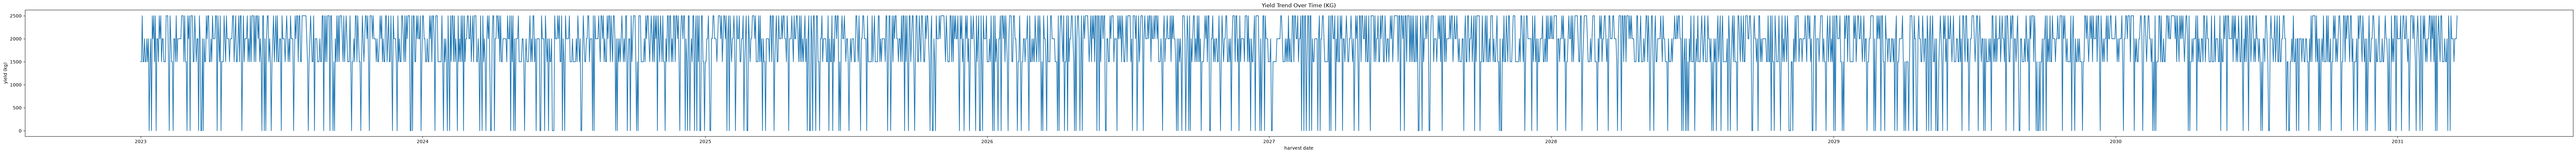

In [21]:
x = table.index
y = table.values
plt.figure(figsize=(100,5))
plt.plot(x,y)
plt.xlabel("harvest date")
plt.ylabel("yield (kg)")
plt.title("Yield Trend Over Time (KG)")
plt.show()